# Exploration of resampling flag variables.

There are 2 flag variables in L2_LR_SSH Unsmoothed
- `ancillary_surface_classification_flag`: ubyte containing 7 mutually exclusive flags
- `ssh_karin_2_qual`: uint containing 21 independant boolean flags

In [1]:
%matplotlib inline

import cartopy.crs as ccrs
import healpix_geo.nested
import matplotlib.pyplot as plt
import numpy as np
import tol_colors as tc
import xarray as xr

from healpix_plot import HealpixGrid
from healpix_resample import BilinearResampler, PSFResampler
from matplotlib.colors import ListedColormap

from swot_healpix.data import SWOT
from swot_healpix.healpix_pcolormesh import healpix_pcolormesh

In [2]:
# 15: 198m
# 10: 6.3km
level = 15

healpix_grid = HealpixGrid(level=level, indexing_scheme="nested", ellipsoid="WGS84")

track = SWOT(cycle=546, track=19, version="PGC0")

In [3]:
swot_file = track.get_file()
swath = xr.open_dataset(swot_file, group="left", chunks=-1)

# Select interesting part

# Warrnambool (southern australia)
# swath = swath.isel(num_lines=slice(22_550, 22_800))

# Upstart bay (northern australia)
swath = swath.isel(num_lines=slice(31_500, 32_000))

swath = swath.dropna("num_pixels", subset=["longitude", "latitude"])

# Left swath, we flip to have ascending longitude
swath = swath.isel(num_pixels=slice(None, None, -1))
if track.pass_type == "descending":
    swath = swath.isel(num_lines=slice(None, None, -1))

swath

<xarray.Dataset> Size: 12MB
Dimensions:                                (num_lines: 500, num_pixels: 233)
Coordinates:
    latitude                               (num_lines, num_pixels) float64 932kB dask.array<chunksize=(500, 233), meta=np.ndarray>
    longitude                              (num_lines, num_pixels) float64 932kB dask.array<chunksize=(500, 233), meta=np.ndarray>
Dimensions without coordinates: num_lines, num_pixels
Data variables: (12/16)
    time                                   (num_lines) datetime64[ns] 4kB dask.array<chunksize=(500,), meta=np.ndarray>
    time_tai                               (num_lines) datetime64[ns] 4kB dask.array<chunksize=(500,), meta=np.ndarray>
    latitude_uncert                        (num_lines, num_pixels) float64 932kB dask.array<chunksize=(500, 233), meta=np.ndarray>
    longitude_uncert                       (num_lines, num_pixels) float64 932kB dask.array<chunksize=(500, 233), meta=np.ndarray>
    polarization_karin                     (num_lines) object 4kB dask.array<chunksize=(500,), meta=np.ndarray>
    ssh_karin_2                            (num_lines, num_pixels) float64 932kB dask.array<chunksize=(500, 233), meta=np.ndarray>
    ...                                     ...
    sig0_karin_uncert                      (num_lines, num_pixels) float32 466kB dask.array<chunksize=(500, 233), meta=np.ndarray>
    total_coherence                        (num_lines, num_pixels) float64 932kB dask.array<chunksize=(500, 233), meta=np.ndarray>
    mean_sea_surface_cnescls               (num_lines, num_pixels) float64 932kB dask.array<chunksize=(500, 233), meta=np.ndarray>
    miti_power_250m                        (num_lines, num_pixels) float32 466kB dask.array<chunksize=(500, 233), meta=np.ndarray>
    miti_power_var_250m                    (num_lines, num_pixels) float32 466kB dask.array<chunksize=(500, 233), meta=np.ndarray>
    ancillary_surface_classification_flag  (num_lines, num_pixels) float32 466kB dask.array<chunksize=(500, 233), meta=np.ndarray>
Attributes:
    description:  Unsmoothed SSH measurement data and related information for...

# Surface classification

The plan is to resample as float, then round to the nearest integer.

In [4]:
classification = swath.ancillary_surface_classification_flag
class_meanings = classification.flag_meanings.split()
print(class_meanings)
classification

['open_ocean', 'land', 'continental_water', 'aquatic_vegetation', 'continental_ice_snow', 'floating_ice', 'salted_basin']


<xarray.DataArray 'ancillary_surface_classification_flag' (num_lines: 500,
                                                           num_pixels: 233)> Size: 466kB
dask.array<getitem, shape=(500, 233), dtype=float32, chunksize=(500, 233), chunktype=numpy.ndarray>
Coordinates:
    latitude   (num_lines, num_pixels) float64 932kB dask.array<chunksize=(500, 233), meta=np.ndarray>
    longitude  (num_lines, num_pixels) float64 932kB dask.array<chunksize=(500, 233), meta=np.ndarray>
Dimensions without coordinates: num_lines, num_pixels
Attributes:
    long_name:      surface classification
    standard_name:  status_flag
    source:         MODIS/GlobCover
    institution:    European Space Agency
    flag_meanings:  open_ocean land continental_water aquatic_vegetation cont...
    flag_values:    [0 1 2 3 4 5 6]
    valid_min:      0
    valid_max:      6
    comment:        7-state surface type classification computed from a mask ...

In [5]:
colors = [
    tc.muted.indigo,  # open_ocean,
    tc.muted.sand,  # land,
    tc.muted.cyan,  # continental_water,
    tc.muted.teal,  # aquatic_vegetation,
    tc.muted.purple,  # continental_ice_snow,
    tc.muted.wine,  # floating_ice,
    tc.muted.rose,  # salted_basin,
    "r", # invalid
]

class_cmap = ListedColormap(colors[:-1])
class_cmap_inv = ListedColormap(colors)

## Naive approach

Simply resample the classification value. This could lead to non-sensical values.
For instance open-ocean (value 0) pixels neighboring floating-ice (value 5) pixels could create values in between.

In [6]:
lon = swath.longitude.values.ravel()
lat = swath.latitude.values.ravel()
class_1d = classification.values.ravel()
ssh_1d = swath.ssh_karin_2.values.ravel()

In [7]:
resampler = PSFResampler(
    lon_deg=lon,
    lat_deg=lat,
    level=level,
    verbose=True,
    sigma_m=300
)

class_hp = resampler.resample(class_1d, lam=0.1)
ssh_hp = resampler.resample(ssh_1d, lam=0.1)

[PSFResampler] area not provided and no shared-latitude-ring structure detected: falling back to a uniform weight of 1.0 per sample.
[KNeighborsResampler] dropping 286 retained cell(s) that passed the wide-neighbourhood 'threshold' test but were never selected by any sample's own Npt-nearest search (would otherwise silently read back as 0.0 for any input).


/home/chaeck/.micromamba/envs/swot-healpix/lib/python3.14/site-packages/healpix_resample/psf.py:346: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /home/conda/feedstock_root/build_artifacts/libtorch_1784990603925/work/aten/src/ATen/Context.cpp:816.)
  M_coo = torch.sparse_coo_tensor(
/home/chaeck/.micromamba/envs/swot-healpix/lib/python3.14/site-packages/healpix_resample/psf.py:570: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at /home/conda/feedstock_root/build_artifacts/libtorch_1784990603925/work/aten/src/ATen/S

Itt 0 : 113
Itt 4 : 0.4058
Itt 8 : 0.002804
Itt 12 : 1.815e-05
Itt 16 : 1.308e-07
Itt 20 : 8.761e-10
Itt 24 : 6.058e-12
Final Itt 28 : 4.016e-14
Itt 0 : 4.729e+04
Itt 4 : 373.6
Itt 8 : 2.898
Itt 12 : 0.0195
Itt 16 : 0.0001346
Itt 20 : 9.079e-07
Itt 24 : 6.319e-09
Itt 28 : 4.335e-11
Final Itt 29 : 1.235e-11


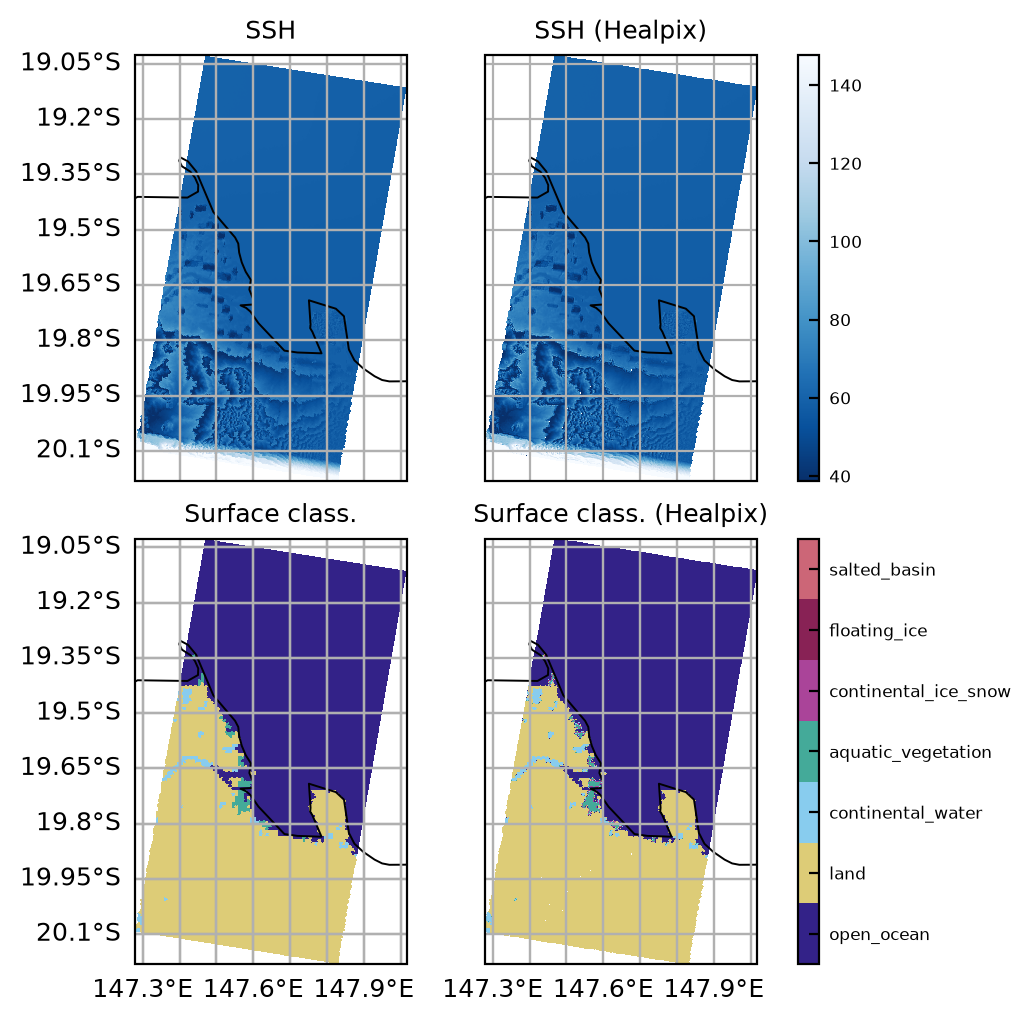

In [15]:
fig, axes = plt.subplots(
    2,
    2,
    subplot_kw={"projection": ccrs.PlateCarree()},
    figsize=(5, 5),
    dpi=200,
    layout="constrained",
    sharex=True,
    sharey=True,
)

ssh_vmin = float(swath.ssh_karin_2.quantile(0.01))
ssh_vmax = float(swath.ssh_karin_2.quantile(0.99))

# SSH
im_ssh = swath.ssh_karin_2.plot.pcolormesh(
    x="longitude",
    y="latitude",
    ax=axes[0, 0],
    cmap="Blues_r",
    vmin=ssh_vmin,
    vmax=ssh_vmax,
    add_colorbar=False,
)
axes[0, 0].set_title("SSH")

# SSH Healpix
healpix_pcolormesh(
    ssh_hp.cell_ids,
    ssh_hp.cell_data,
    healpix_grid=healpix_grid,
    level_tile=7,
    cmap="Blues_r",
    vmin=ssh_vmin,
    vmax=ssh_vmax,
    ax=axes[0, 1],
)
fig.colorbar(im_ssh, ax=axes[0])
axes[0, 1].set_title("SSH (Healpix)")

# Classification
im_cls = classification.plot.pcolormesh(
    x="longitude",
    y="latitude",
    ax=axes[1, 0],
    cmap=class_cmap,
    vmin=0,
    vmax=7,
    add_colorbar=False,
)
axes[1, 0].set_title("Surface class.")

# Classification (Healpix)
healpix_pcolormesh(
    class_hp.cell_ids,
    np.rint(class_hp.cell_data),
    healpix_grid=healpix_grid,
    level_tile=7,
    vmin=0,
    vmax=7,
    cmap=class_cmap,
    ax=axes[1, 1],
)
cbar = fig.colorbar(im_cls, ax=axes[1], ticks=np.arange(0, 7) + 0.5)
cbar.set_ticklabels(class_meanings)
axes[1, 1].set_title("Surface class. (Healpix)")

for ax in axes.flat:
    ax.coastlines(lw=0.7)
    ax.set_aspect("equal")
    ax.gridlines()

for ax in axes[:, 0]:
    ax.gridlines(draw_labels={"left": "y"})
for ax in axes[-1]:
    ax.gridlines(draw_labels={"bottom": "x"})

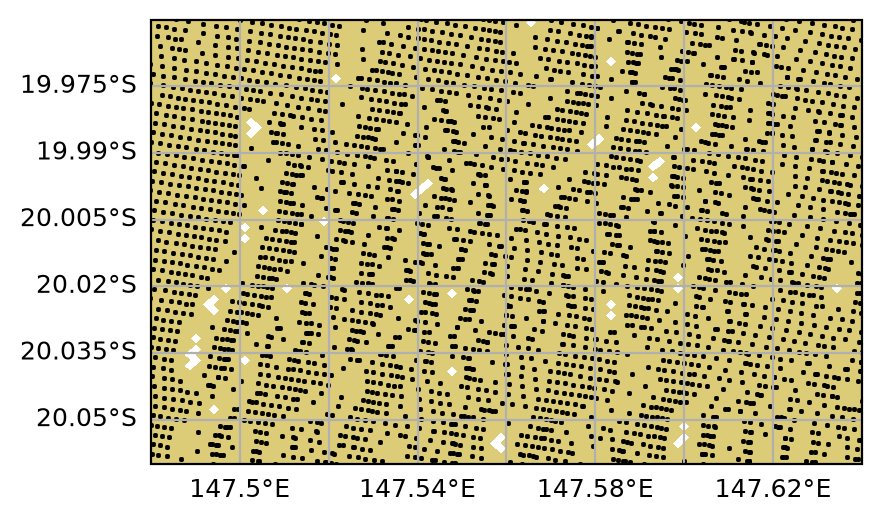

In [16]:
# Show postings to explain missing cells over land (due to layovers)

fig, ax = plt.subplots(
    subplot_kw={"projection": ccrs.PlateCarree()},
    figsize=(5, 2.5),
    dpi=200,
    layout="constrained",
)

healpix_pcolormesh(
    class_hp.cell_ids,
    np.rint(class_hp.cell_data),
    healpix_grid=healpix_grid,
    level_tile=7,
    vmin=0,
    vmax=7,
    cmap=class_cmap,
)

ax.scatter(
    swath.longitude,
    swath.latitude,
    marker="s",
    c="k",
    s=1,
)

ax.set_xlim(147.48, 147.64)
ax.set_ylim(-20.06, -19.96)

ax.coastlines(lw=0.7)
ax.set_aspect("equal")
ax.gridlines(draw_labels={"left": "y", "bottom": "x"})

(0.0, 233.0)

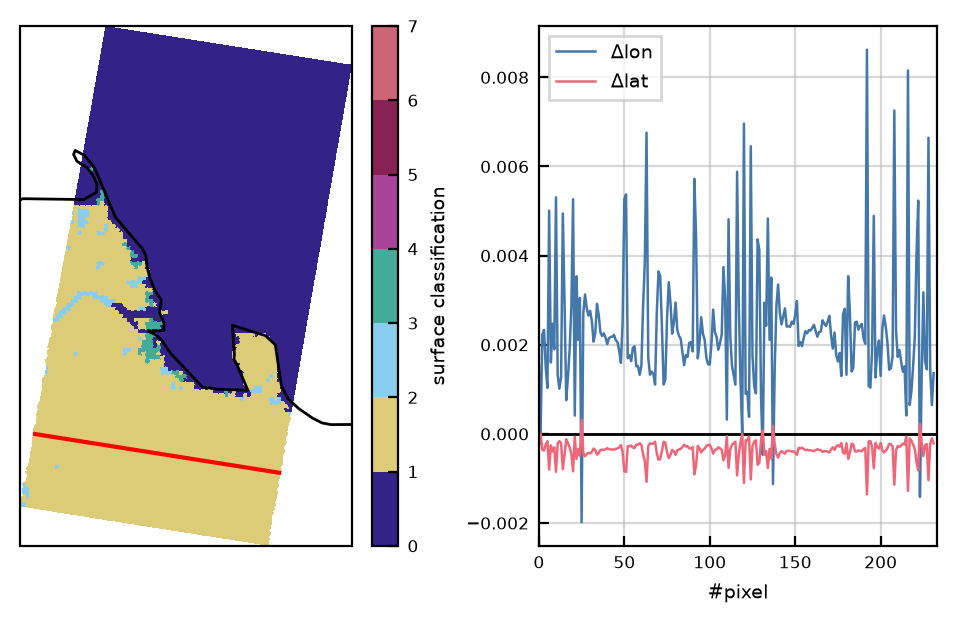

In [29]:
# Show coordinates along a line

i_line = 75

line_lon = swath.longitude.isel(num_lines=i_line)
line_lat = swath.latitude.isel(num_lines=i_line)

fig = plt.figure(
    layout="constrained",
    figsize=(5, 3),
    dpi=200,
)

ax1 = fig.add_subplot(121, projection=ccrs.PlateCarree())
ax2 = fig.add_subplot(122)

classification.plot.pcolormesh(
    x="longitude", y="latitude", vmin=0, vmax=7, cmap=class_cmap, ax=ax1
)
ax1.plot(line_lon, line_lat, color="r")
ax1.set_aspect("equal")
ax1.coastlines()

ax2.axhline(0, color="k", lw=1)
ax2.plot(line_lon.diff("num_pixels"), lw=0.9, color=tc.bright.blue, label="Δlon")
ax2.plot(line_lat.diff("num_pixels"), lw=0.9, color=tc.bright.red, label="Δlat")
ax2.legend()

ax2.set_xlabel("#pixel")
ax2.set_xlim(0, len(line_lon))

## Better approach

If we only resample the value and round to nearest integer, we risk interpolating non-sensical values. Especially open_ocean (0) and floating_ice (5) risk being interpreted as any category between the two.

Idea: extract each flag as a boolean, resample that, then recombine. We may need an additional "no category" flag.

To recombine: I have seven values, I take the highest one. If it is below a threshold, mark it as invalid / uncategorized. This happens on land when there is layover, pixels gets assigned a wrong value (open-ocean).

In [30]:
value_mask = xr.DataArray(classification.flag_values, dims=("flag"))
class_flags = value_mask == classification

In [31]:
lon = swath.longitude.values.ravel()
lat = swath.latitude.values.ravel()
class_flags_1d = class_flags.values.reshape(class_flags.flag.size, -1)
assert class_flags_1d.shape == (len(class_meanings), lon.size)

In [32]:
resampler = PSFResampler(lon_deg=lon, lat_deg=lat, level=level, sigma_m=300)

result = []
for flag, data in zip(class_meanings, class_flags_1d):
    resampled = resampler.resample(data, lam=0.1)
    result.append(resampled.cell_data)
    print(f"Resampled {flag}, {resampled.cg_niters} iterations, "
          f"residual {resampled.cg_residual_norms[-1]}")

class_flags_hp_psf = xr.DataArray(
    np.array(result),
    dims=("flag", "cell_ids"),
    coords={"flag": class_flags.flag, "cell_ids": resampler.cell_ids},
)

Resampled open_ocean, 29 iterations, residual [9.290544e-08]
Resampled land, 29 iterations, residual [1.2124183e-07]
Resampled continental_water, 29 iterations, residual [8.258795e-08]
Resampled aquatic_vegetation, 29 iterations, residual [6.298097e-08]
Resampled continental_ice_snow, 0 iterations, residual 0.0
Resampled floating_ice, 0 iterations, residual 0.0
Resampled salted_basin, 0 iterations, residual 0.0


In [33]:
resampler = BilinearResampler(lon_deg=lon, lat_deg=lat, level=level)
result = resampler.resample(class_flags_1d)

class_flags_hp_bl = xr.DataArray(
    result.cell_data,
    dims=("flag", "cell_ids"),
    coords={"flag": class_flags.flag, "cell_ids": result.cell_ids},
)

[KNeighborsResampler] dropping 409 retained cell(s) that passed the wide-neighbourhood 'threshold' test but were never selected by any sample's own Npt-nearest search (would otherwise silently read back as 0.0 for any input).


In [34]:
class_hp_psf = class_flags_hp_psf.argmax("flag")
class_invalid_hp_psf = class_flags_hp_psf[class_hp_psf] < 0.1
class_hp_psf = class_hp_psf.where(~class_invalid_hp_psf, 7)
print(f"PSF: Found {int((class_hp_psf == 7).sum())} values with no categories")

class_hp_bl = class_flags_hp_bl.argmax("flag")
class_invalid_hp_bl = class_flags_hp_bl[class_hp_bl] < 0.1
class_hp_bl = class_hp_bl.where(~class_invalid_hp_bl, 7)
print(f"Bilin.: Found {int((class_hp_bl == 7).sum())} values with no categories")

PSF: Found 0 values with no categories
Bilin.: Found 0 values with no categories


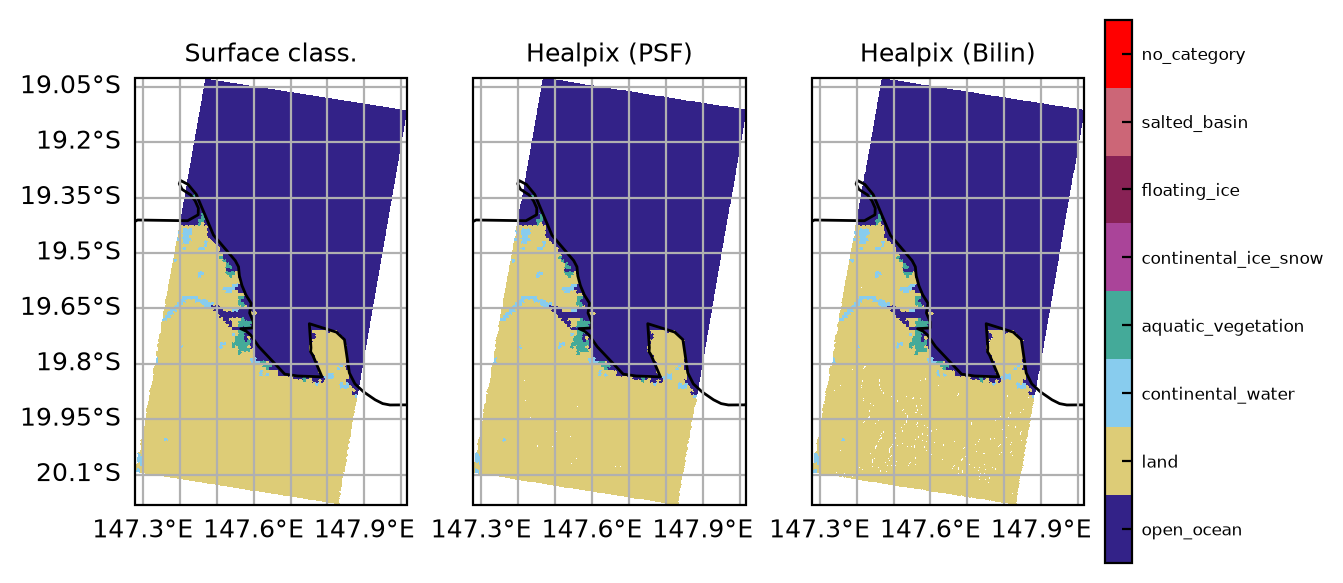

In [35]:
fig, axes = plt.subplots(
    1,
    3,
    sharex=True,
    sharey=True,
    subplot_kw={"projection": ccrs.PlateCarree()},
    figsize=(6.6, 2.8),
    dpi=200,
    layout="constrained",
)

# Classification
im_cls = classification.plot.pcolormesh(
    x="longitude",
    y="latitude",
    ax=axes[0],
    cmap=class_cmap_inv,
    vmin=0,
    vmax=8,
    add_colorbar=False,
)
axes[0].set_title("Surface class.")

# Healpix PSF
healpix_pcolormesh(
    class_hp_psf.cell_ids,
    class_hp_psf.astype("f"),
    healpix_grid=healpix_grid,
    level_tile=7,
    vmin=0,
    vmax=8,
    cmap=class_cmap_inv,
    ax=axes[1],
)
axes[1].set_title("Healpix (PSF)")

# Healpix Bilin
healpix_pcolormesh(
    class_hp_bl.cell_ids,
    class_hp_bl.astype("f"),
    healpix_grid=healpix_grid,
    level_tile=7,
    vmin=0,
    vmax=8,
    cmap=class_cmap_inv,
    ax=axes[2],
)
axes[2].set_title("Healpix (Bilin)")

cbar = fig.colorbar(im_cls, ax=axes[2], ticks=np.arange(0, 8) + 0.5)
cbar.set_ticklabels(class_meanings + ["no_category"])

for ax in axes:
    ax.set_aspect("equal")
    ax.coastlines()

axes[0].gridlines(draw_labels={"left": "y", "bottom": "x"})
for ax in axes[1:]:
    ax.gridlines(draw_labels={"bottom": "x"})

# Quality flags

In [36]:
qual_flags = swath.ssh_karin_2_qual
qual_meanings = qual_flags.flag_meanings.split()
print(qual_meanings)
qual_flags

['suspect_large_ssh_delta', 'suspect_large_ssh_std', 'suspect_large_ssh_window_std', 'suspect_beam_used', 'suspect_less_than_nine_beams', 'suspect_ssb_out_of_range', 'suspect_karin_telem', 'suspect_orbit_control', 'suspect_sc_event_flag', 'suspect_tvp_qual', 'suspect_volumetric_corr', 'degraded_ssb_not_computable', 'degraded_media_delays_missing', 'degraded_beam_used', 'degraded_large_attitude', 'degraded_karin_ifft_overflow', 'bad_karin_telem', 'bad_very_large_attitude', 'bad_outside_of_range', 'degraded', 'bad_not_usable']


<xarray.DataArray 'ssh_karin_2_qual' (num_lines: 500, num_pixels: 233)> Size: 932kB
dask.array<getitem, shape=(500, 233), dtype=float64, chunksize=(500, 233), chunktype=numpy.ndarray>
Coordinates:
    latitude   (num_lines, num_pixels) float64 932kB dask.array<chunksize=(500, 233), meta=np.ndarray>
    longitude  (num_lines, num_pixels) float64 932kB dask.array<chunksize=(500, 233), meta=np.ndarray>
Dimensions without coordinates: num_lines, num_pixels
Attributes:
    long_name:      quality flag for sea surface height from KaRIn
    standard_name:  status_flag
    flag_meanings:  suspect_large_ssh_delta suspect_large_ssh_std suspect_lar...
    flag_masks:     [         1          2          4          8         16  ...
    valid_min:      0
    valid_max:      3809459807
    comment:        Quality flag for sea surface height from KaRIn in ssh_kar...

In [37]:
bit_mask = xr.DataArray(qual_flags.flag_masks, dims=("flag"), coords={"flag": qual_meanings})
qual_flags = (bit_mask & qual_flags.astype("uint")).astype("bool")

In [38]:
# only look at variables that are not all false
variables = qual_flags.flag[(qual_flags.sum(["num_lines", "num_pixels"]) > 0).values].values

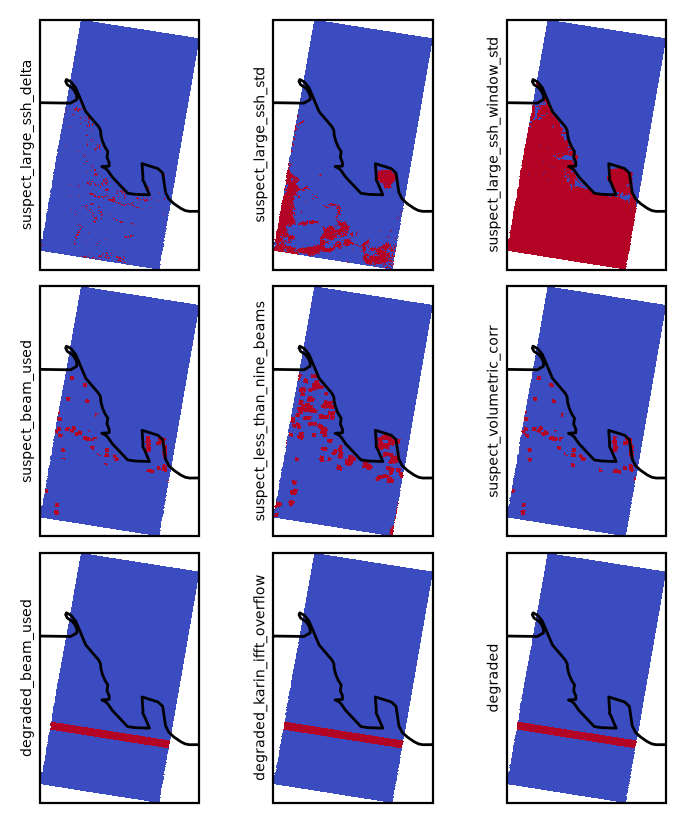

In [39]:
fig, axes = plt.subplots(
    3,
    len(variables)//3,
    figsize=(3.5, 4),
    dpi=200,
    layout="constrained",
    sharex=True,
    sharey=True,
    subplot_kw={"projection": ccrs.PlateCarree()},
)

for flag, ax in zip(variables, axes.flat):
    ax.pcolormesh(
        qual_flags.longitude,
        qual_flags.latitude,
        qual_flags.sel(flag=flag),
        cmap="coolwarm",
    )
    ax.annotate(
        flag,
        xy=(0, 0.5),
        xycoords="axes fraction",
        xytext=(-2, 0),
        textcoords="offset points",
        ha="right",
        va="center",
        rotation=90,
        fontsize=5
    )
    ax.set_aspect("equal")
    ax.coastlines()

In [40]:
lon = swath.longitude.values.ravel()
lat = swath.latitude.values.ravel()
qual_flags_1d = qual_flags.values.reshape(qual_flags.flag.size, -1)
assert qual_flags_1d.shape == (len(qual_meanings), lon.size)

In [41]:
resampler = PSFResampler(
    lon_deg=lon,
    lat_deg=lat,
    level=level,
    verbose=False,
    sigma_m=300,
)

result = []
for flag, data in zip(qual_meanings, qual_flags_1d):
    resampled = resampler.resample(data, lam=0.2)
    result.append(resampled.cell_data)
    print(f"Resampled {flag}, {resampled.cg_niters} iterations, "
          f"residual {resampled.cg_residual_norms[-1]}")

qual_flags_hp = xr.DataArray(
    np.array(result),
    dims=("flag", "cell_ids"),
    coords={"flag": qual_flags.flag, "cell_ids": resampler.cell_ids},
)
qual_flags_hp = qual_flags_hp > 0.3

Resampled suspect_large_ssh_delta, 22 iterations, residual [7.762485e-08]
Resampled suspect_large_ssh_std, 22 iterations, residual [9.871706e-08]
Resampled suspect_large_ssh_window_std, 21 iterations, residual [1.3483614e-07]
Resampled suspect_beam_used, 21 iterations, residual [1.11938874e-07]
Resampled suspect_less_than_nine_beams, 21 iterations, residual [1.631182e-07]
Resampled suspect_ssb_out_of_range, 0 iterations, residual 0.0
Resampled suspect_karin_telem, 0 iterations, residual 0.0
Resampled suspect_orbit_control, 0 iterations, residual 0.0
Resampled suspect_sc_event_flag, 0 iterations, residual 0.0
Resampled suspect_tvp_qual, 0 iterations, residual 0.0
Resampled suspect_volumetric_corr, 21 iterations, residual [1.160019e-07]
Resampled degraded_ssb_not_computable, 0 iterations, residual 0.0
Resampled degraded_media_delays_missing, 0 iterations, residual 0.0
Resampled degraded_beam_used, 21 iterations, residual [4.2720387e-08]
Resampled degraded_large_attitude, 0 iterations, re

Text(0.5, 1.0, 'Healpix')

findfont: Failed to find font weight semibold, now using 700.


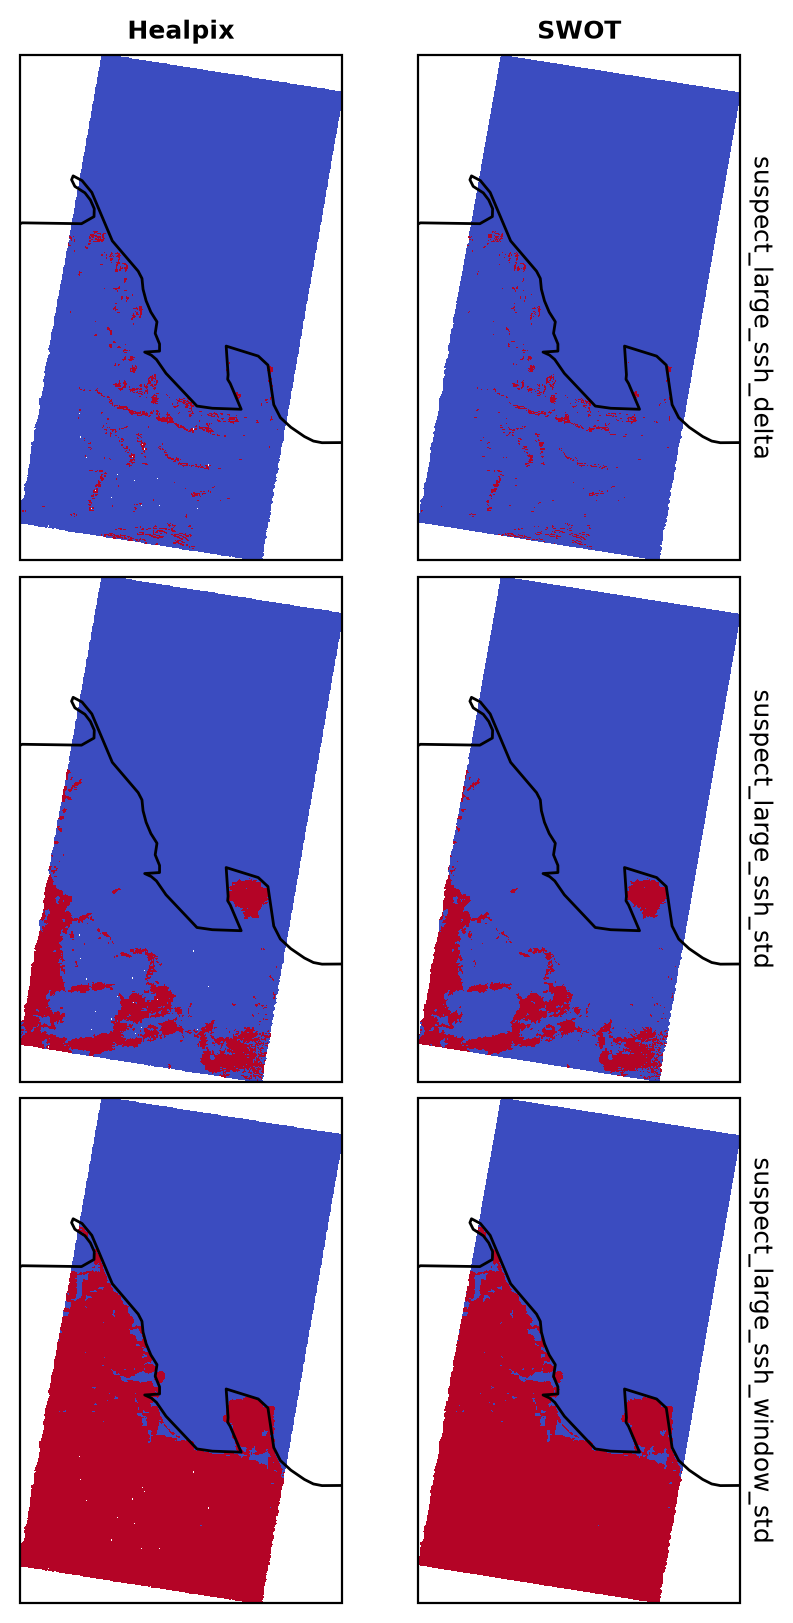

In [49]:
flags_to_plot = [
    "suspect_large_ssh_delta",
    "suspect_large_ssh_std",
    "suspect_large_ssh_window_std",
]

fig, axes = plt.subplots(
    len(flags_to_plot),
    2,
    figsize=(4, 2 + 2 * len(flags_to_plot)),
    dpi=200,
    layout="constrained",
    sharex=True,
    sharey=True,
    subplot_kw={"projection": ccrs.PlateCarree()},
)

xlim = [float(qual_flags.longitude.min()), float(qual_flags.longitude.max())]
ylim = [float(qual_flags.latitude.min()), float(qual_flags.latitude.max())]

for i_flag, flag in enumerate(flags_to_plot):
    ax1, ax2 = axes[i_flag, :]

    ax2.pcolormesh(
        qual_flags.longitude,
        qual_flags.latitude,
        qual_flags.sel(flag=flag),
        cmap="coolwarm",
        transform=ccrs.PlateCarree(),
    )

    healpix_pcolormesh(
        qual_flags_hp.cell_ids,
        qual_flags_hp.sel(flag=flag).astype("f"),
        healpix_grid=healpix_grid,
        level_tile=7,
        vmin=0,
        vmax=1,
        cmap="coolwarm",
        ax=ax1
    )

    ax2.annotate(
        flag,
        xy=(1, 0.5),
        xycoords="axes fraction",
        xytext=(3, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        rotation=-90,
    )

    for ax in (ax1, ax2):
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        ax.set_aspect("equal")
        ax.coastlines()

axes[0, 1].set_title("SWOT", weight="semibold")
axes[0, 0].set_title("Healpix", weight="semibold")

## Repack

In [55]:
shift = np.arange(qual_flags_hp.flag.size)
repacked = np.left_shift(qual_flags_hp.values, shift[:, None])